In [1]:
import getpass, os
os.environ["FIRMS_KEY"] = getpass.getpass("Masukkan MAP_KEY: ")

In [2]:
import requests
KEY = os.environ["FIRMS_KEY"]
r = requests.get("https://firms.modaps.eosdis.nasa.gov/mapserver/mapkey_status/", params={"MAP_KEY": KEY})
print(r.status_code)
print(r.text)

200
{ "transaction_limit" : 5000, "current_transactions": 0, "transaction_interval" : "10 minutes" }


In [3]:
r = requests.get(f"https://firms.modaps.eosdis.nasa.gov/api/data_availability/csv/{KEY}/ALL")
print(r.text[:1500])

data_id,min_date,max_date
MODIS_NRT,2026-08-01,2026-10-21
MODIS_SP,2000-11-01,2026-07-31
VIIRS_NOAA20_NRT,2026-07-01,2026-10-21
VIIRS_NOAA20_SP,2018-04-01,2026-06-30
VIIRS_NOAA21_NRT,2024-01-17,2026-10-20
VIIRS_NOAA21_SP,2023-03-01,2026-06-30
VIIRS_SNPP_NRT,2026-07-01,2026-10-20
VIIRS_SNPP_SP,2012-01-20,2026-06-30
LANDSAT_NRT,2022-06-20,2026-10-20
GOES_NRT,2022-08-09,2026-10-21
BA_MODIS,2000-11-01,2026-07-01
BA_VIIRS,2012-03-01,2026-07-01


In [ ]:
import os, io, time, requests, pandas as pd
from datetime import date, timedelta

KEY = os.environ["FIRMS_KEY"]
BBOX = "94,-11.5,141.5,6.5"        # seluruh Indonesia
OUT = "data/hotspot_raw"
os.makedirs(OUT, exist_ok=True)

KEEP = ["latitude","longitude","acq_date","acq_time","confidence","frp","bright_ti4","daynight","satellite"]

def tarik_5hari(source, start, n):
    u = f"https://firms.modaps.eosdis.nasa.gov/api/area/csv/{KEY}/{source}/{BBOX}/{n}/{start.isoformat()}"
    for coba in range(3):
        try:
            r = requests.get(u, timeout=120)
            if r.ok:
                if not r.text.strip() or r.text.lstrip().startswith("<"):
                    return pd.DataFrame()
                return pd.read_csv(io.StringIO(r.text))
        except requests.RequestException:
            pass
        time.sleep(5 * (coba + 1))
    raise RuntimeError(f"Gagal: {source} {start}")

def tarik_bulan(source, tahun, bulan, awal_global, akhir_global):
    path = f"{OUT}/{source}_{tahun}-{bulan:02d}.parquet"
    if os.path.exists(path):          # sudah ada, lewati
        return
    cur = max(date(tahun, bulan, 1), awal_global)
    akhir = date(tahun + (bulan == 12), bulan % 12 + 1, 1) - timedelta(days=1)
    akhir = min(akhir, akhir_global)
    bag = []
    while cur <= akhir:
        n = min(5, (akhir - cur).days + 1)
        d = tarik_5hari(source, cur, n)
        if len(d):
            bag.append(d[[c for c in KEEP if c in d.columns]])
        cur += timedelta(days=n)
        time.sleep(0.2)
    if bag:
        pd.concat(bag, ignore_index=True).to_parquet(path, index=False)
    print(source, tahun, bulan, sum(len(b) for b in bag))

def tarik_semua(source, mulai, selesai):
    y, m = mulai.year, mulai.month
    while date(y, m, 1) <= selesai:
        tarik_bulan(source, y, m, mulai, selesai)   # <- sekarang 5 argumen
        m += 1
        if m == 13:
            y, m = y + 1, 1

def tarik_semua(source, mulai, selesai):
    y, m = mulai.year, mulai.month
    while date(y, m, 1) <= selesai:
        tarik_bulan(source, y, m, selesai)
        m += 1
        if m == 13: y, m = y + 1, 1

In [5]:
import os, io, zipfile, requests

URL = "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_IDN_1.json.zip"

if not os.path.exists("gadm41_IDN_1.json"):
    r = requests.get(URL, timeout=120)
    r.raise_for_status()
    zipfile.ZipFile(io.BytesIO(r.content)).extractall(".")

print(os.getcwd())
print(os.path.exists("gadm41_IDN_1.json"))

c:\Users\Lenovo\OneDrive - Politeknik Elektronika Negeri Surabaya\PENS ANJAY\SEMESTER 5\PROJEK SISTEM CERDAS\HotSpot
True


2,133,656 baris | 103 file | Apr 2018 - Oct 2026 | 9 kolom
Total null: 0
Kolom: latitude, longitude, acq_date, acq_time, confidence, frp, bright_ti4, daynight, satellite
confidence
n    1927958
l     138865
h      66833
Name: count, dtype: int64
pulau
Kalimantan              33.6
Sumatera                18.2
Luar Indonesia          14.4
Maluku & Papua          11.8
Bali & Nusa Tenggara     9.9
Sulawesi                 6.9
Jawa                     5.2
Name: proportion, dtype: float64


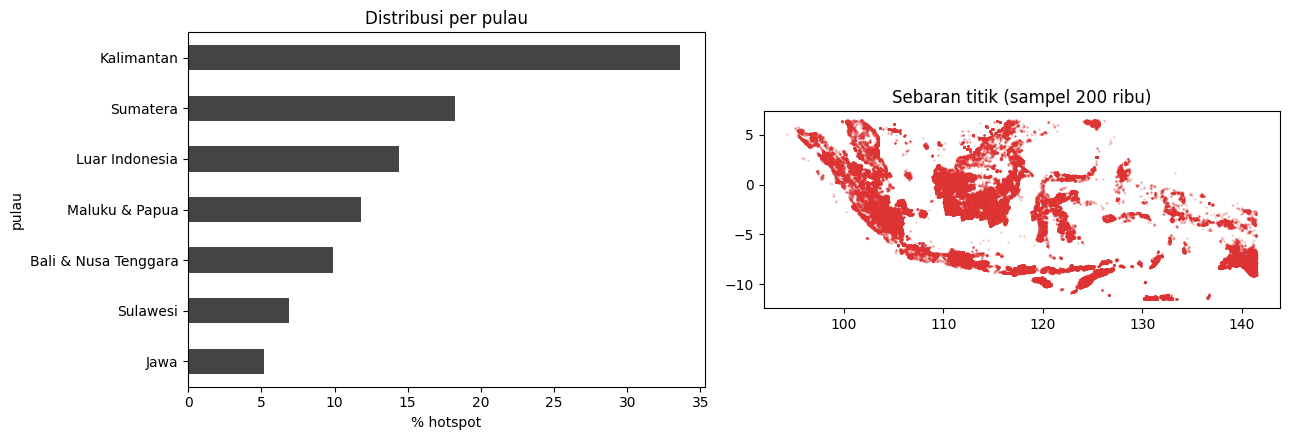

In [6]:
import glob
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. Gabung semua file bulanan
files = sorted(glob.glob("data/hotspot_raw/*.parquet"))
df = pd.concat((pd.read_parquet(f) for f in files), ignore_index=True)
df["acq_date"] = pd.to_datetime(df["acq_date"])

# 2. Angka utama (bahan slide)
print(f"{len(df):,} baris | {len(files)} file | "
      f"{df['acq_date'].min():%b %Y} - {df['acq_date'].max():%b %Y} | {df.shape[1]} kolom")
print("Total null:", int(df.isna().sum().sum()))
print("Kolom:", ", ".join(df.columns))
print(df["confidence"].value_counts())

# 3. Titik -> provinsi -> pulau
prov = gpd.read_file("gadm41_IDN_1.json")[["NAME_1", "geometry"]]
pts = gpd.GeoDataFrame(
    df[["longitude", "latitude"]],
    geometry=gpd.points_from_xy(df["longitude"], df["latitude"]),
    crs="EPSG:4326",
)
j = gpd.sjoin(pts, prov, how="left", predicate="within")
df["provinsi"] = j["NAME_1"].groupby(level=0).first()

PULAU = {
    "Sumatera": ["aceh", "sumatera", "riau", "jambi", "bengkulu", "lampung", "bangka"],
    "Jawa": ["jawa", "banten", "jakarta", "yogyakarta"],
    "Kalimantan": ["kalimantan"],
    "Sulawesi": ["sulawesi", "gorontalo"],
    "Bali & Nusa Tenggara": ["bali", "nusatenggara"],
    "Maluku & Papua": ["maluku", "papua"],
}

def ke_pulau(p):
    if pd.isna(p):
        return "Luar Indonesia"
    p = p.lower().replace(" ", "")
    for nama, kunci in PULAU.items():
        if any(k in p for k in kunci):
            return nama
    return "Lainnya"

df["pulau"] = df["provinsi"].map(ke_pulau)
dist = df["pulau"].value_counts(normalize=True).mul(100).round(1)
print(dist)

# 4. Visual: bar per pulau + peta sebaran titik
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
dist.sort_values().plot.barh(ax=ax[0], color="#444")
ax[0].set_xlabel("% hotspot")
ax[0].set_title("Distribusi per pulau")

s = df.sample(200_000, random_state=42)
ax[1].scatter(s["longitude"], s["latitude"], s=0.3, alpha=0.3, c="#d33")
ax[1].set_aspect("equal")
ax[1].set_title("Sebaran titik (sampel 200 ribu)")

plt.tight_layout()
plt.savefig("gambaran_data.png", dpi=200)

In [7]:
df_id = df[df["pulau"] != "Luar Indonesia"].copy()
print(f"{len(df_id):,} baris di dalam Indonesia")
df_id["pulau"].value_counts(normalize=True).mul(100).round(1)

1,825,700 baris di dalam Indonesia


pulau
Kalimantan              39.2
Sumatera                21.3
Maluku & Papua          13.8
Bali & Nusa Tenggara    11.6
Sulawesi                 8.0
Jawa                     6.0
Name: proportion, dtype: float64

In [8]:
from datetime import date

tarik_semua("VIIRS_SNPP_SP", date(2012, 1, 20), date(2018, 3, 31))

TypeError: tarik_bulan() missing 1 required positional argument: 'akhir_global'